# Bi 2021 — Kidney RCC · 03 signatures
Read the embryonic-module geography along the trajectory and decide **Gate 2**. Signature maps show **raw** `score_genes` values (the deliverable convention); geography and gradient are read off the graph-smoothed scores computed in 02.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
from numpy.linalg import svd
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast':'Gastrulation', 'pSom':'Somitogenesis', 'Crest':'Neural Crest'}
print('cells:', adata.shape[0], '| scores present:', [m for m in modules if m in adata.obs])
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.dropna().drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')

cells: 7822 | scores present: ['Gast', 'pSom', 'Crest']
Gast: 72/81 genes present
pSom: 83/98 genes present
Crest: 96/104 genes present


### Gate 2 — module geography and terminal Crest
Non-branching signature: Gast and pSom **co-vary** (both decline from the root) rather than diverging into two competing arms, and **Crest rises to the terminus** as the inverse gradient. Gate 3 is NA (no bifurcation to test).

In [4]:
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
lo = adata.obs['pSom_sm'] >= adata.obs['pSom_sm'].quantile(0.9)
print(f'Neural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')
print(f'Somite/Gast-high decile mean pseudotime = {tn[lo.values].mean():.2f} (origin if ~0)')
print('Gate 2: shared developmental gradient (Gast/pSom co-vary) + inverse terminal Crest -> GO (non-branching)')
print('Gate 3: no bifurcation -> NA')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.34
  Crest_sm vs Gast_sm: r = +0.07
  Crest_sm vs pSom_sm: r = -0.65
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.156
  pSom_sm: rho = -0.463
  Crest_sm: rho = +0.711
Neural-crest-high decile mean pseudotime = 0.83 (terminal if ~1)
Somite/Gast-high decile mean pseudotime = 0.22 (origin if ~0)
Gate 2: shared developmental gradient (Gast/pSom co-vary) + inverse terminal Crest -> GO (non-branching)
Gate 3: no bifurcation -> NA


### Signature maps (raw scores, house linear layout)

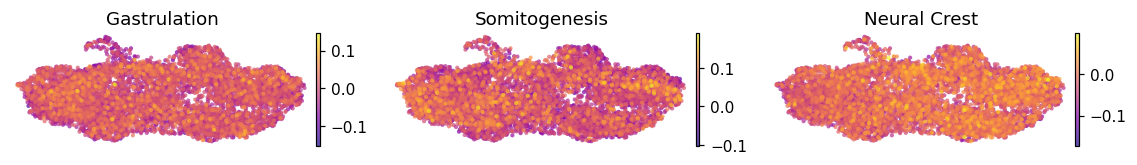

In [5]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, axes = plt.subplots(1, 3, figsize=(10.5,1.6))
for ax,(m,title) in zip(axes, modules.items()):
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc='right',
               frameon=False, show=False, ax=ax, title=title)
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
fig.tight_layout()

### Deliverables — per-module `*_signature.pdf` + colorbars

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


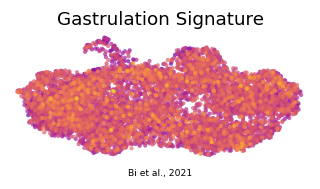

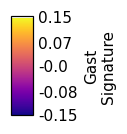

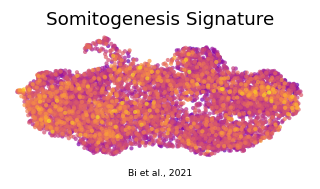

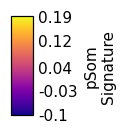

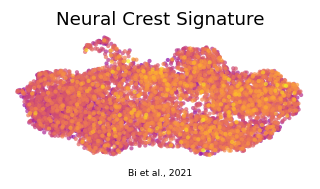

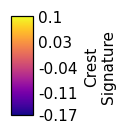

In [6]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Bi et al., 2021', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')

In [7]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (7822, 25001)
